# LEAF-1 AUC by ctDNA level in one cancer type

Reads tables from `../data/` and writes figures to `../output/`.
Source analysis: `../../NOTEBOOK_PROVENANCE.tsv`.

Companion to Fig. 5f (`cfdna_ctdna_bin_auc` in leaf-1-figures
`cfdna/notebook/cfdna_ctdna_detection.ipynb`), which averages the per-cancer AUCs
over the seven cancers. This panel shows the per-cancer AUCs for one cancer.

ctDNA level is the ichorCNA tumor-fraction tertile, taken over all cancer
samples with a tumor fraction **pooled across the seven cancers** (207 samples),
exactly as in the original notebook. The bins are therefore not balanced within
any one cancer. Each bin's AUC is that bin's cancer samples against all healthy
controls of the same `<cancer>_cancer_vs_healthy` task, scored on the
out-of-fold `prob_ensemble`. Percentages are of that cancer's samples.

Set `CANCER` in the next cell to draw a different cancer type.

Panel:
- `cfdna_ctdna_bin_auc_breast`: LEAF-1 ROC AUC vs healthy per ctDNA tertile.

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from notebook/, from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA.relative_to(_p))
print("OUT :", OUT.relative_to(_p))

DATA: cfdna/data
OUT : cfdna/output


In [2]:
# ── Constants, ctDNA tertiles, per-bin AUC ────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator
from sklearn.metrics import roc_auc_score

CANCER = "Breast"   # Bile_duct, Breast, Colorectal, Gastric, Lung, Ovarian, Pancreatic
SCORE = "prob_ensemble"
BIN_ORDER = ["low_ctDNA", "medium_ctDNA", "high_ctDNA"]
BIN_LABELS = {"low_ctDNA": "Low", "medium_ctDNA": "Medium", "high_ctDNA": "High"}

df = pd.read_csv(DATA / "cfdna_ctdna_vs_healthy_predictions.csv", float_precision="round_trip")

# Tertiles over every cancer sample with a tumor fraction, pooled across cancers.
pos_all = (df[(df["label"] == 1) & df["ichorcna_tumor_fraction"].notna()]
           [["sample_id", "ichorcna_tumor_fraction"]].drop_duplicates("sample_id"))
pos_all["ctdna_bin"] = pd.qcut(pos_all["ichorcna_tumor_fraction"], q=3,
                               labels=BIN_ORDER).astype("object")
print(f"{len(pos_all)} cancer samples with a tumor fraction, pooled tertiles:")
print(pos_all.groupby("ctdna_bin")["ichorcna_tumor_fraction"]
      .agg(["count", "min", "max"]).reindex(BIN_ORDER).to_string())

task = df[df["cancer"] == CANCER].merge(pos_all[["sample_id", "ctdna_bin"]],
                                        on="sample_id", how="left")
healthy = task[task["label"] == 0]
cases = task[task["label"] == 1]
n_cases = len(cases)
n_no_tf = int(cases["ctdna_bin"].isna().sum())

rows = []
for b in BIN_ORDER:
    pos = cases[cases["ctdna_bin"] == b]
    m = pd.concat([pos, healthy], ignore_index=True)
    auc = float(roc_auc_score(m["label"], m[SCORE])) if len(pos) else np.nan
    tf = pos_all.loc[pos_all["ctdna_bin"] == b, "ichorcna_tumor_fraction"]
    rows.append({"cancer": CANCER, "ctdna_bin": b, "ctdna_label": BIN_LABELS[b],
                 "tf_bin_min": float(tf.min()), "tf_bin_max": float(tf.max()),
                 "n_cancer": len(pos), "pct_of_cancer": 100 * len(pos) / n_cases,
                 "n_healthy": len(healthy), "leaf1_auc": auc})
summary = pd.DataFrame(rows)
print(f"\n{CANCER}: {n_cases} cancer samples ({n_no_tf} without a tumor fraction), "
      f"{len(healthy)} healthy controls")
print(summary.to_string(index=False))

207 cancer samples with a tumor fraction, pooled tertiles:
              count      min      max
ctdna_bin                            
low_ctDNA        69  0.00000  0.01032
medium_ctDNA     69  0.01129  0.02967
high_ctDNA       69  0.02980  0.69180

Breast: 54 cancer samples (0 without a tumor fraction), 172 healthy controls
cancer    ctdna_bin ctdna_label  tf_bin_min  tf_bin_max  n_cancer  pct_of_cancer  n_healthy  leaf1_auc
Breast    low_ctDNA         Low     0.00000     0.01032        21      38.888889        172   0.908915
Breast medium_ctDNA      Medium     0.01129     0.02967        25      46.296296        172   0.928023
Breast   high_ctDNA        High     0.02980     0.69180         8      14.814815        172   0.982558


saved: cfdna/output/cfdna_ctdna_bin_auc_breast.pdf
saved: cfdna/output/cfdna_ctdna_bin_auc_breast.png
saved: cfdna/output/cfdna_ctdna_bin_auc_breast.svg
saved: cfdna/output/cfdna_ctdna_bin_auc_breast.tsv


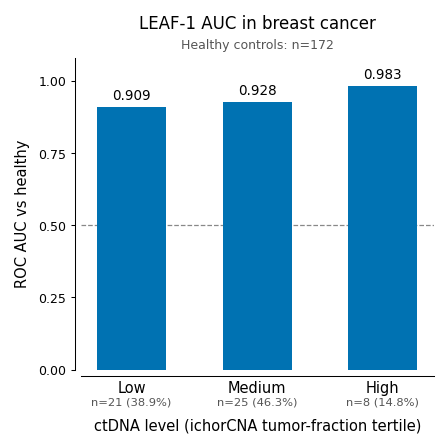

In [3]:
# ── Figure: LEAF-1 AUC vs healthy per ctDNA tertile ────────────────────────────
PANEL_RC = {"xtick.labelsize": 7, "ytick.labelsize": 6}
BLUE = OKABE_ITO["blue"]
with plt.rc_context(PANEL_RC):
    fig, ax = plt.subplots(figsize=(3.0, 3.0))
    x = np.arange(len(summary))
    ax.axhline(0.5, color="#888888", linestyle="--", linewidth=0.6, zorder=1)
    ax.bar(x, summary["leaf1_auc"], width=0.55, color=BLUE, linewidth=0, zorder=2)
    for xi, v in zip(x, summary["leaf1_auc"]):
        ax.text(xi, v + 0.015, f"{v:.3f}", ha="center", va="bottom", fontsize=6.5)

    ax.set_xticks(x)
    ax.set_xticklabels(summary["ctdna_label"], fontsize=7)
    for xi, r in zip(x, summary.itertuples()):
        ax.annotate(f"n={r.n_cancer} ({r.pct_of_cancer:.1f}%)", xy=(xi, 0),
                    xycoords=("data", "axes fraction"), xytext=(0, -13),
                    textcoords="offset points", ha="center", va="top",
                    fontsize=5.5, color="#555555")
    ax.set_xlabel("ctDNA level (ichorCNA tumor-fraction tertile)", fontsize=7, labelpad=11)
    ax.set_ylim(0, 1.08)
    ax.yaxis.set_major_locator(FixedLocator([0, 0.25, 0.5, 0.75, 1.0]))
    ax.set_ylabel("ROC AUC vs healthy")
    ax.set_title(f"LEAF-1 AUC in {CANCER.replace('_', ' ').lower()} cancer",
                 fontsize=8, pad=14)
    ax.text(0.5, 1.02, f"Healthy controls: n={len(healthy)}", transform=ax.transAxes,
            ha="center", va="bottom", fontsize=6, color="#555555")
    ax.spines["left"].set_position(("outward", 3))
    ax.spines["bottom"].set_position(("outward", 3))
    ax.tick_params(axis="both", which="both", length=2, pad=2)
    ax.tick_params(axis="x", length=0)
    fig.tight_layout()

    savefig(fig, OUT, f"cfdna_ctdna_bin_auc_{CANCER.lower()}", data=summary)
    plt.show()